# SafeWalk · Machine Learning
## Quando um atropelamento em São Paulo tende a ser grave ou fatal?

**Global Solution FIAP 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**

O SafeWalk ajuda quem anda a pé por São Paulo, principalmente à noite. O app já mostra no mapa os sinistros com pedestre do **Infosiga (Detran-SP)**, mas um ponto no mapa não diz *quão perigoso* aquele tipo de situação costuma ser.

**Pergunta de ML (classificação binária):** dado um sinistro de trânsito com pedestre na capital paulista, considerando **quando** (hora, dia da semana, mês), **onde** (tipo de via, quem administra, coordenadas) e **o que estava envolvido** (moto, carro, ônibus, caminhão), o sinistro teve **vítima grave ou fatal**?

| Item | Escolha |
|---|---|
| Dados | Infosiga / Detran-SP, arquivos públicos `sinistros_*.csv` (CC BY 4.0) |
| Recorte | Município de São Paulo (IBGE 3550308), sinistros com pedestre, 2019 em diante |
| Alvo | `grave_ou_fatal = 1` se `qtd_gravidade_fatal + qtd_gravidade_grave > 0` |
| Modelo | XGBoost (gradient boosting em árvores) |
| Divisão | **temporal**: treino 2019–2024, teste 2025–2026 |
| Validação | `StratifiedKFold` (5 dobras) **somente no treino** |
| Busca | 18 combinações de 3 hiperparâmetros (`max_depth`, `learning_rate`, `n_estimators`) |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
                             roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
import sklearn, xgboost

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1


## 1. Problema e dados reais

**Fonte:** Infosiga SP, Detran-SP — <https://infosiga.detran.sp.gov.br/> · download direto: <https://infosiga.detran.sp.gov.br/painel/download/file/dados_infosiga.zip> · licença CC BY 4.0.

O ZIP oficial é grande e contém também arquivos de pessoas e veículos. O script `preparar_dados.py` lê **apenas** `sinistros_*.csv`, filtra a capital, sinistros com pedestre e registros de sinistro (descarta `NOTIFICACAO`, que não tem gravidade apurada) e grava `dados/processed/atropelamentos_sp_capital.csv`. Detalhes em `dados/README.md`.

In [2]:
PROCESSADO = Path("dados/processed/atropelamentos_sp_capital.csv")
BRUTO = Path("dados/raw/dados_infosiga.zip")
if not PROCESSADO.exists():
    import subprocess, sys
    subprocess.run([sys.executable, "preparar_dados.py", str(BRUTO)], check=True)

df_raw = pd.read_csv(PROCESSADO, dtype=str)
print(f"{len(df_raw):,} sinistros com pedestre na capital")
df_raw.head(3).T

31,139 sinistros com pedestre na capital


,0,1,2
id_sinistro,2026893,1658288,1399254
tipo_registro,SINISTRO NAO FATAL,SINISTRO NAO FATAL,SINISTRO NAO FATAL
data_sinistro,01/01/2019,02/01/2019,04/01/2019
ano_sinistro,2019,2019,2019
mes_sinistro,01,01,01
dia_sinistro,01,02,04
hora_sinistro,02:49,22:59,17:51
dia_da_semana,Terça-feira,Quarta-feira,Sexta-feira
turno,MADRUGADA,NOITE,TARDE
tipo_via,VIAS URBANAS,VIAS URBANAS,VIAS URBANAS


In [3]:
num_cols = [c for c in df_raw.columns if c.startswith("qtd_")] + ["ano_sinistro", "mes_sinistro", "dia_sinistro"]
df = df_raw.copy()
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df[[c for c in df.columns if c.startswith("qtd_")]] = df[[c for c in df.columns if c.startswith("qtd_")]].fillna(0)
for c in ["latitude", "longitude"]:
    df[c] = pd.to_numeric(df[c].str.replace(",", ".", regex=False), errors="coerce")
df["data"] = pd.to_datetime(df["data_sinistro"], format="%d/%m/%Y", errors="coerce")

periodo = f"{df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}"
print("Período coberto:", periodo)
print(df.groupby(["ano_sinistro", "tipo_registro"]).size().unstack(fill_value=0))

Período coberto: 01/01/2019 a 31/10/2026
tipo_registro  SINISTRO FATAL  SINISTRO NAO FATAL
ano_sinistro                                     
2019                      347                4233
2020                      252                3415
2021                      243                3473
2022                      303                3819
2023                      355                3830
2024                      390                3992
2025                      418                3198
2026                      346                2525


### 1.1 Alvo e qualidade dos dados

In [4]:
df["grave_ou_fatal"] = ((df["qtd_gravidade_fatal"] + df["qtd_gravidade_grave"]) > 0).astype(int)
# Sinistros sem nenhuma gravidade apurada (tudo "não disponível") não permitem dizer o rótulo
sem_info = (df[["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve", "qtd_gravidade_ileso"]].sum(axis=1) == 0)
print(f"Sem gravidade apurada (removidos): {sem_info.sum():,} ({sem_info.mean():.1%})")
df = df[~sem_info].copy()

print("Valores ausentes relevantes (%):")
print((df[["hora_sinistro", "latitude", "longitude", "tipo_via", "dia_da_semana"]].isna().mean() * 100).round(2))
print(f"\nTaxa de grave/fatal: {df['grave_ou_fatal'].mean():.1%} de {len(df):,} sinistros")

Sem gravidade apurada (removidos): 551 (1.8%)
Valores ausentes relevantes (%):
hora_sinistro    0.34
latitude         3.33
longitude        3.33
tipo_via         0.00
dia_da_semana    0.00
dtype: float64

Taxa de grave/fatal: 19.0% de 30,588 sinistros


### 1.2 Limpeza e variáveis

* **Hora:** `hora_sinistro` (`HH:MM`) → hora inteira.
* **Coordenadas:** fora da caixa da capital (`lon -46.83…-46.36`, `lat -24.01…-23.36`) são tratadas como ausentes, nunca inventadas.
* **Registros incompletos removidos:** hora ausente é 100% fatal; `tipo_via`/`circunscricao` “NAO DISPONIVEL” ficam entre 73% e 100% graves; coordenada ausente ~38%. O campo vazio “denuncia” o fluxo de registro de óbitos. Treinamos só com registros completos (célula abaixo mostra a evidência).
* **Removidas por serem específicas demais/redundantes:** `administracao` e `conservacao` (nome da concessionária) — `tipo_via` e `circunscricao` já dizem se é rodovia e de que esfera.
* **Vazamento direto evitado:** `tipo_registro` (diz se foi fatal), `qtd_gravidade_*`, `tp_sinistro_primario` e `id_sinistro` **não entram** como variáveis.
* **Vazamento pelo processo de registro (descoberto na exploração):** sinistros fatais e não fatais chegam ao Infosiga por fluxos diferentes e são preenchidos de forma diferente. `qtd_veic_outros > 0` aparece em ~20% dos fatais e ~2% dos não fatais; `tipo_local = NAO DISPONIVEL` é 3× mais comum nos não fatais; `qtd_pedestre` vem 0 ou 2 em parte dos atropelamentos. Essas colunas descrevem **como o caso foi registrado**, não a rua, e seriam desconhecidas para o app no momento do aviso. Foram **removidas** (célula abaixo mostra a evidência).
* **Dia da semana:** a fonte grava `Terça-feira`; normalizado para `Terça`.
* **Categóricas** (`dia_da_semana`, `tipo_via`, `circunscricao`): one-hot, ignorando categorias novas no teste.

In [5]:
print("Evidência de vazamento pelo registro (% por tipo de registro):")
print(pd.crosstab(df["qtd_veic_outros"].clip(0, 1), df["tipo_registro"], normalize="columns").round(3))
print(pd.crosstab(df["tipo_local"].fillna("NAO DISPONIVEL"), df["tipo_registro"], normalize="columns").round(3))
df["hora"] = pd.to_numeric(df["hora_sinistro"].str.slice(0, 2), errors="coerce")
df.loc[~df["hora"].between(0, 23), "hora"] = np.nan
fora = ~(df["longitude"].between(-46.83, -46.36) & df["latitude"].between(-24.01, -23.36))
print(f"Coordenadas fora da capital/ausentes → NaN: {fora.sum():,}")
df.loc[fora, ["latitude", "longitude"]] = np.nan

# Campos ausentes também vazam o alvo: o fluxo de registro de óbitos chega com menos campos preenchidos
flags = pd.DataFrame({
    "hora ausente": df["hora"].isna(),
    "coordenada ausente/fora": df["latitude"].isna(),
    "tipo_via não disponível": df["tipo_via"].fillna("NAO DISPONIVEL").eq("NAO DISPONIVEL"),
    "circunscrição não disponível": ~df["circunscricao"].isin(["MUNICIPAL", "ESTADUAL", "FEDERAL"]),
})
print("% grave/fatal quando o campo está incompleto × completo:")
print(pd.DataFrame({c: [df.loc[flags[c], "grave_ou_fatal"].mean(), df.loc[~flags[c], "grave_ou_fatal"].mean(), flags[c].sum()]
                    for c in flags}, index=["incompleto", "completo", "n incompletos"]).T.round(3))
completo = ~flags.any(axis=1)
print(f"\nMantidos apenas registros completos: {completo.sum():,} de {len(df):,} ({completo.mean():.1%})")
df = df[completo].copy()
df["dia_da_semana"] = df["dia_da_semana"].str.replace("-feira", "", regex=False)
df["noite"] = df["hora"].isin([19, 20, 21, 22, 23, 0, 1, 2, 3, 4, 5]).astype(int)
df["fim_de_semana"] = df["dia_da_semana"].isin(["Sábado", "Domingo"]).astype(int)
df["mes"] = df["mes_sinistro"]
df["veic_pesado"] = ((df["qtd_onibus"] + df["qtd_caminhao"]) > 0).astype(int)

CAT = ["dia_da_semana", "tipo_via", "circunscricao"]
NUM = ["hora", "noite", "fim_de_semana", "mes", "latitude", "longitude",
       "qtd_bicicleta", "qtd_motocicleta", "qtd_automovel", "qtd_onibus", "qtd_caminhao", "veic_pesado"]
for c in CAT:
    df[c] = df[c].fillna("NAO DISPONIVEL")

Evidência de vazamento pelo registro (% por tipo de registro):
tipo_registro    SINISTRO FATAL  SINISTRO NAO FATAL
qtd_veic_outros                                    
0.0                       0.804               0.982
1.0                       0.196               0.018


tipo_registro   SINISTRO FATAL  SINISTRO NAO FATAL
tipo_local                                        
NAO DISPONIVEL           0.058               0.156
PRIVADO                  0.015               0.010
PUBLICO                  0.927               0.834
Coordenadas fora da capital/ausentes → NaN: 1,038
% grave/fatal quando o campo está incompleto × completo:
                              incompleto  completo  n incompletos
hora ausente                       1.000     0.187          104.0
coordenada ausente/fora            0.378     0.183         1038.0
tipo_via não disponível            1.000     0.184          216.0
circunscrição não disponível       0.793     0.184          305.0

Mantidos apenas registros completos: 29,410 de 30,588 (96.1%)


### 1.3 Exploração: o que os dados já mostram

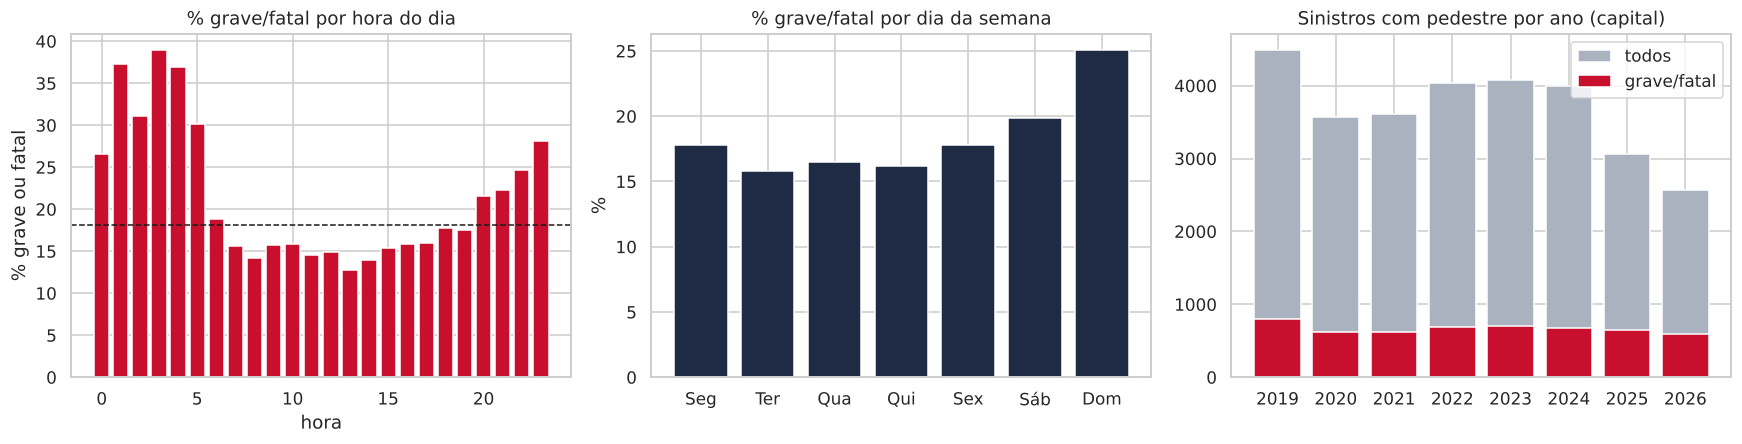

hora     0.0      1.0      2.0      3.0     4.0      5.0      6.0       7.0   \
mean    0.266    0.372    0.311    0.389    0.37    0.301    0.188     0.157   
size  538.000  333.000  241.000  190.000  303.00  545.000  942.000  1315.000   

hora      8.0       9.0   ...     14.0      15.0      16.0     17.0      18.0  \
mean     0.142     0.157  ...     0.14     0.154     0.158     0.16     0.178   
size  1272.000  1266.000  ...  1563.00  1609.000  1662.000  1746.00  2343.000   

hora      19.0      20.0      21.0      22.0     23.0  
mean     0.175     0.216     0.223     0.247    0.281  
size  2296.000  1697.000  1325.000  1058.000  680.000  

[2 rows x 24 columns]


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
por_hora = df[df["hora"] >= 0].groupby("hora")["grave_ou_fatal"].agg(["mean", "size"])
axes[0].bar(por_hora.index, por_hora["mean"] * 100, color="#C8102E")
axes[0].set(title="% grave/fatal por hora do dia", xlabel="hora", ylabel="% grave ou fatal")
axes[0].axhline(df["grave_ou_fatal"].mean() * 100, ls="--", c="k", lw=1)

dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
por_dia = df.groupby("dia_da_semana")["grave_ou_fatal"].mean().reindex([d for d in dias if d in df["dia_da_semana"].unique()])
axes[1].bar(por_dia.index.str[:3], por_dia.values * 100, color="#1F2A44")
axes[1].set(title="% grave/fatal por dia da semana", ylabel="%")

ano = df.groupby("ano_sinistro").agg(total=("grave_ou_fatal", "size"), graves=("grave_ou_fatal", "sum"))
axes[2].bar(ano.index.astype(int), ano["total"], color="#AAB2C0", label="todos")
axes[2].bar(ano.index.astype(int), ano["graves"], color="#C8102E", label="grave/fatal")
axes[2].set(title="Sinistros com pedestre por ano (capital)"); axes[2].legend()
plt.tight_layout(); plt.savefig(FIG / "01_exploracao.png", bbox_inches="tight"); plt.show()
print(por_hora.round(3).T)

## 2. Modelo e preparação

### 2.1 Por que XGBoost

* Os dados são **tabulares e mistos** (categorias de via, contagens de veículos, hora, coordenadas). Árvores com boosting são o estado da arte nesse formato e não exigem normalização.
* Capta **interações** que importam aqui (ex.: madrugada × via expressa × caminhão) sem criá-las à mão.
* Lida bem com **desbalanceamento** via `scale_pos_weight`.
* Dá importância de variáveis para explicar ao cidadão o porquê.
* Alternativas descartadas: MLP/LSTM pediriam mais dados e não há sequência temporal por indivíduo; KMeans+PCA não responde a uma pergunta supervisionada; Random Forest seria viável, mas costuma ficar abaixo do boosting em dados tabulares.

### 2.2 Divisão treino/teste temporal

Treinamos com **2019–2024** e testamos com **2025–2026**, simulando o uso real: o modelo aprende com o passado e é avaliado em sinistros que ainda não tinha visto. O teste não é tocado durante a busca de hiperparâmetros.

In [7]:
treino = df[df["ano_sinistro"] <= 2024]
teste = df[df["ano_sinistro"] >= 2025]
X_tr, y_tr = treino[CAT + NUM], treino["grave_ou_fatal"]
X_te, y_te = teste[CAT + NUM], teste["grave_ou_fatal"]
resumo_split = pd.DataFrame({
    "linhas": [len(X_tr), len(X_te)],
    "% grave/fatal": [y_tr.mean() * 100, y_te.mean() * 100],
    "período": [f"{treino['data'].min():%m/%Y}–{treino['data'].max():%m/%Y}",
                f"{teste['data'].min():%m/%Y}–{teste['data'].max():%m/%Y}"],
}, index=["treino", "teste"]).round(2)
resumo_split

,linhas,% grave/fatal,período
treino,23778,17.23,01/2019–12/2024
teste,5632,21.93,01/2025–10/2026


In [8]:
pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT),
    ("num", "passthrough", NUM),
])
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"scale_pos_weight = {spw:.2f} (negativos / positivos no treino)")
pipe = Pipeline([
    ("pre", pre),
    ("xgb", XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                          random_state=SEED, n_jobs=-1)),
])

scale_pos_weight = 4.81 (negativos / positivos no treino)


## 3. Treino com diferentes hiperparâmetros

Três hiperparâmetros, **18 combinações** (3 × 3 × 2), cada uma avaliada com validação cruzada estratificada de 5 dobras **apenas no conjunto de treino** (90 ajustes):

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `max_depth` | 3, 5, 8 | complexidade de cada árvore (mais fundo = mais risco de overfitting) |
| `learning_rate` | 0.03, 0.1, 0.3 | tamanho do passo de cada árvore |
| `n_estimators` | 150, 400 | número de árvores |

**Métrica de escolha: ROC-AUC.** As classes são desbalanceadas, então acurácia engana (um modelo que sempre diz “leve” acertaria a maioria). ROC-AUC mede se o modelo ordena bem os casos graves acima dos leves, independentemente do limiar. Também registramos PR-AUC, recall e F1 da classe grave.

In [9]:
grid = {
    "xgb__max_depth": [3, 5, 8],
    "xgb__learning_rate": [0.03, 0.1, 0.3],
    "xgb__n_estimators": [150, 400],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busca = GridSearchCV(pipe, grid, cv=cv, n_jobs=1, return_train_score=True, refit="roc_auc",
                     scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision",
                              "recall": "recall", "f1": "f1"})
busca.fit(X_tr, y_tr)

res = pd.DataFrame(busca.cv_results_)
tab = res[["param_xgb__max_depth", "param_xgb__learning_rate", "param_xgb__n_estimators",
           "mean_train_roc_auc", "mean_test_roc_auc", "std_test_roc_auc",
           "mean_test_pr_auc", "mean_test_recall", "mean_test_f1", "rank_test_roc_auc"]].copy()
tab.columns = ["max_depth", "learning_rate", "n_estimators", "AUC treino (CV)", "AUC validação (CV)",
               "desvio AUC val", "PR-AUC val", "recall val", "F1 val", "rank"]
tab["gap treino-val"] = tab["AUC treino (CV)"] - tab["AUC validação (CV)"]
tab = tab.sort_values("rank").reset_index(drop=True)
tab.to_csv(FIG / "grid_resultados.csv", index=False)
print("Melhor combinação:", busca.best_params_)
tab.round(4)

Melhor combinação: {'xgb__learning_rate': 0.03, 'xgb__max_depth': 3, 'xgb__n_estimators': 400}


,max_depth,learning_rate,n_estimators,AUC treino (CV),AUC validação (CV),desvio AUC val,PR-AUC val,recall val,F1 val,rank,gap treino-val
0,3,0.03,400,0.6886,0.6435,0.0049,0.3149,0.5247,0.3475,1,0.0451
1,5,0.03,150,0.7061,0.6427,0.0031,0.3117,0.5168,0.3455,2,0.0634
2,3,0.10,150,0.6964,0.6419,0.0044,0.3122,0.5137,0.3437,3,0.0545
3,3,0.03,150,0.6607,0.6417,0.0027,0.3132,0.5378,0.3480,4,0.0191
4,5,0.03,400,0.7858,0.6362,0.0060,0.3071,0.4744,0.3371,5,0.1496
5,3,0.10,400,0.7473,0.6325,0.0065,0.3061,0.4919,0.3361,6,0.1148
6,8,0.03,150,0.8373,0.6309,0.0026,0.2999,0.4148,0.3240,7,0.2064
7,5,0.10,150,0.8038,0.6298,0.0068,0.3024,0.4624,0.3314,8,0.1740
8,3,0.30,150,0.7460,0.6283,0.0083,0.2997,0.4932,0.3336,9,0.1178
9,8,0.03,400,0.9618,0.6108,0.0062,0.2887,0.3235,0.2928,10,0.3510


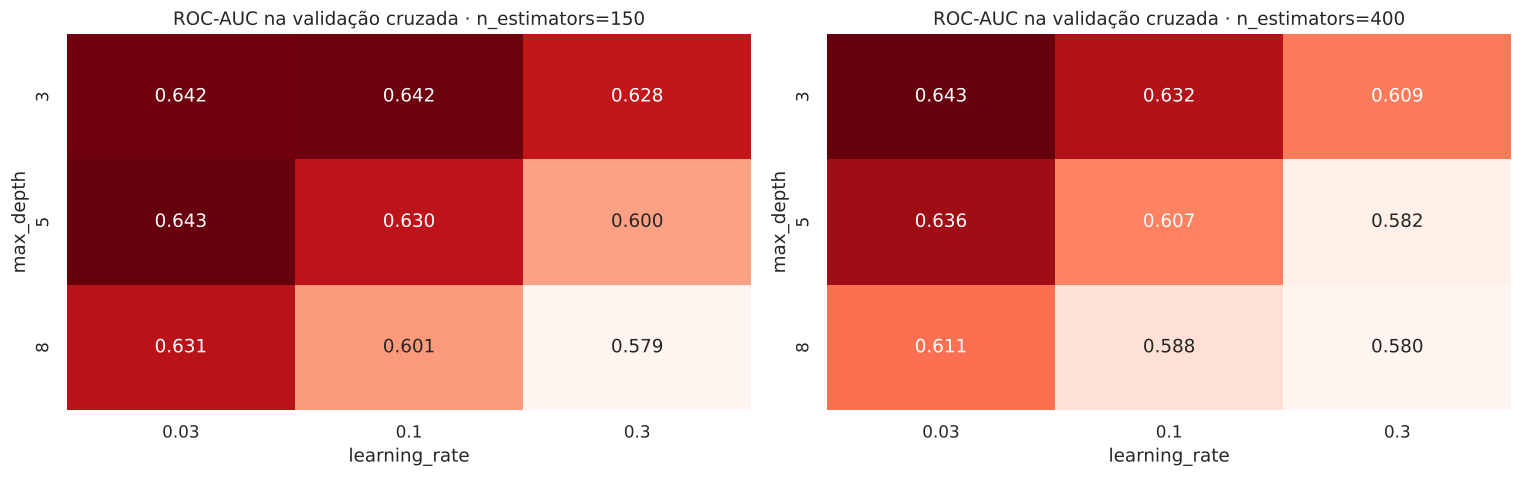

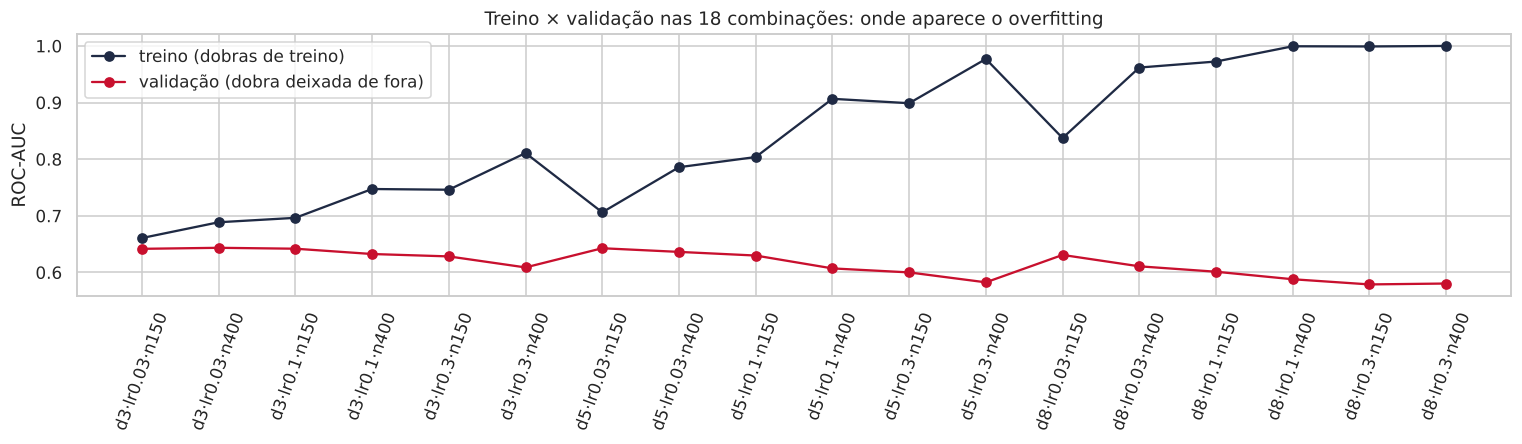

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, n in zip(axes, [150, 400]):
    piv = tab[tab["n_estimators"] == n].pivot(index="max_depth", columns="learning_rate", values="AUC validação (CV)")
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="Reds", ax=ax, cbar=False)
    ax.set(title=f"ROC-AUC na validação cruzada · n_estimators={n}")
plt.tight_layout(); plt.savefig(FIG / "02_grid_heatmap.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(14, 4.2))
t = tab.sort_values(["max_depth", "learning_rate", "n_estimators"]).reset_index(drop=True)
rot = [f"d{r.max_depth}·lr{r.learning_rate}·n{r.n_estimators}" for r in t.itertuples()]
ax.plot(rot, t["AUC treino (CV)"], "o-", label="treino (dobras de treino)", c="#1F2A44")
ax.plot(rot, t["AUC validação (CV)"], "o-", label="validação (dobra deixada de fora)", c="#C8102E")
ax.set(ylabel="ROC-AUC", title="Treino × validação nas 18 combinações: onde aparece o overfitting")
ax.tick_params(axis="x", rotation=70); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_overfitting_grid.png", bbox_inches="tight"); plt.show()

## 4. Resultados em treino e teste

In [11]:
modelo = busca.best_estimator_
baseline = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_tr, y_tr)

def avaliar(m, X, y, limiar=0.5):
    p = m.predict_proba(X)[:, 1]
    yhat = (p >= limiar).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Recall (grave)": recall_score(y, yhat), "Precisão (grave)": precision_score(y, yhat, zero_division=0),
            "F1 (grave)": f1_score(y, yhat), "Acurácia balanceada": balanced_accuracy_score(y, yhat)}

metr = pd.DataFrame({
    "XGBoost · treino": avaliar(modelo, X_tr, y_tr),
    "XGBoost · teste": avaliar(modelo, X_te, y_te),
    "Baseline aleatório · teste": avaliar(baseline, X_te, y_te),
}).round(3)
metr.to_csv(FIG / "metricas_treino_teste.csv")
metr

,XGBoost · treino,XGBoost · teste,Baseline aleatório · teste
ROC-AUC,0.681,0.644,0.498
PR-AUC,0.360,0.351,0.218
Recall (grave),0.568,0.528,0.164
Precisão (grave),0.279,0.311,0.214
F1 (grave),0.374,0.391,0.185
Acurácia balanceada,0.631,0.600,0.498


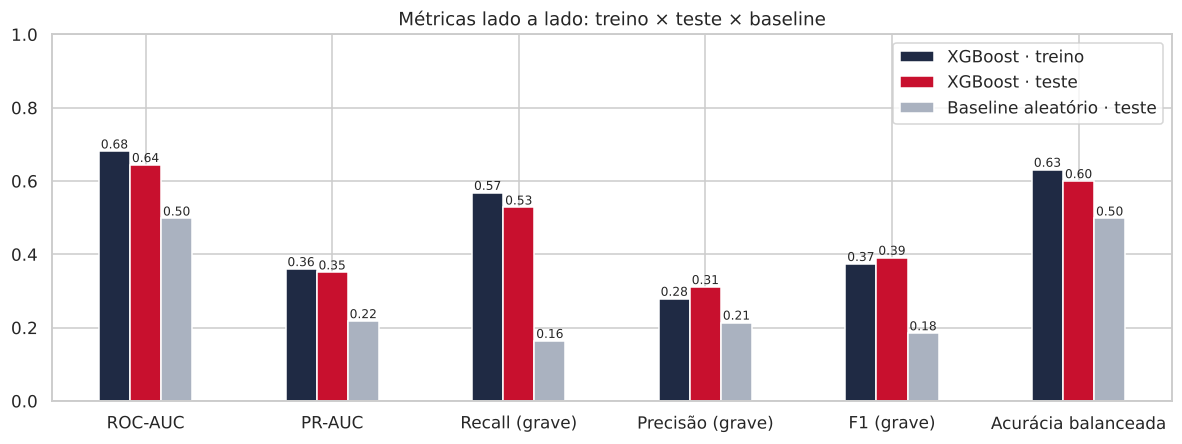

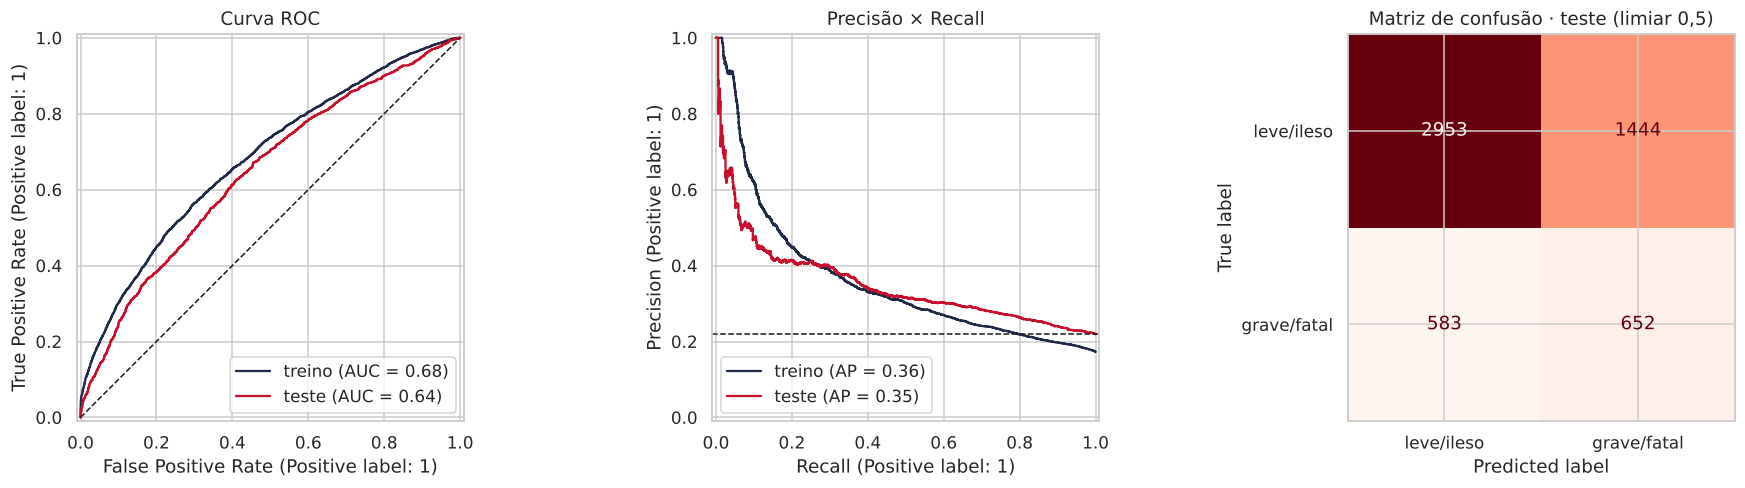

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.2))
metr[["XGBoost · treino", "XGBoost · teste", "Baseline aleatório · teste"]].plot.bar(
    ax=ax, color=["#1F2A44", "#C8102E", "#AAB2C0"], rot=0)
ax.set(ylim=(0, 1), title="Métricas lado a lado: treino × teste × baseline")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "04_metricas_treino_teste.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
RocCurveDisplay.from_estimator(modelo, X_tr, y_tr, ax=axes[0], name="treino", curve_kwargs={"color": "#1F2A44"})
RocCurveDisplay.from_estimator(modelo, X_te, y_te, ax=axes[0], name="teste", curve_kwargs={"color": "#C8102E"})
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("Curva ROC")
PrecisionRecallDisplay.from_estimator(modelo, X_tr, y_tr, ax=axes[1], name="treino", curve_kwargs={"color": "#1F2A44"})
PrecisionRecallDisplay.from_estimator(modelo, X_te, y_te, ax=axes[1], name="teste", curve_kwargs={"color": "#C8102E"})
axes[1].axhline(y_te.mean(), ls="--", c="k", lw=1); axes[1].set_title("Precisão × Recall")
ConfusionMatrixDisplay(confusion_matrix(y_te, modelo.predict(X_te)),
                       display_labels=["leve/ileso", "grave/fatal"]).plot(ax=axes[2], cmap="Reds", colorbar=False)
axes[2].set_title("Matriz de confusão · teste (limiar 0,5)")
plt.tight_layout(); plt.savefig(FIG / "05_roc_pr_confusao.png", bbox_inches="tight"); plt.show()

### 4.1 Overfitting

Comparamos o desempenho em treino e teste do modelo escolhido e também o comportamento das combinações mais complexas na busca (gráfico da seção 3).

In [13]:
gap = metr.loc["ROC-AUC", "XGBoost · treino"] - metr.loc["ROC-AUC", "XGBoost · teste"]
mais_complexa = tab.sort_values(["max_depth", "learning_rate", "n_estimators"]).iloc[-1]
print(f"Modelo escolhido: AUC treino {metr.loc['ROC-AUC','XGBoost · treino']:.3f} | teste {metr.loc['ROC-AUC','XGBoost · teste']:.3f} | gap {gap:.3f}")
print(f"Combinação mais complexa (d=8, lr=0.3, n=400): AUC treino-CV {mais_complexa['AUC treino (CV)']:.3f} × validação {mais_complexa['AUC validação (CV)']:.3f} (gap {mais_complexa['gap treino-val']:.3f})")
print(f"Maior gap da busca: {tab['gap treino-val'].max():.3f} | menor: {tab['gap treino-val'].min():.3f}")

Modelo escolhido: AUC treino 0.681 | teste 0.644 | gap 0.037
Combinação mais complexa (d=8, lr=0.3, n=400): AUC treino-CV 1.000 × validação 0.580 (gap 0.420)
Maior gap da busca: 0.420 | menor: 0.019


### 4.2 O que pesa na previsão

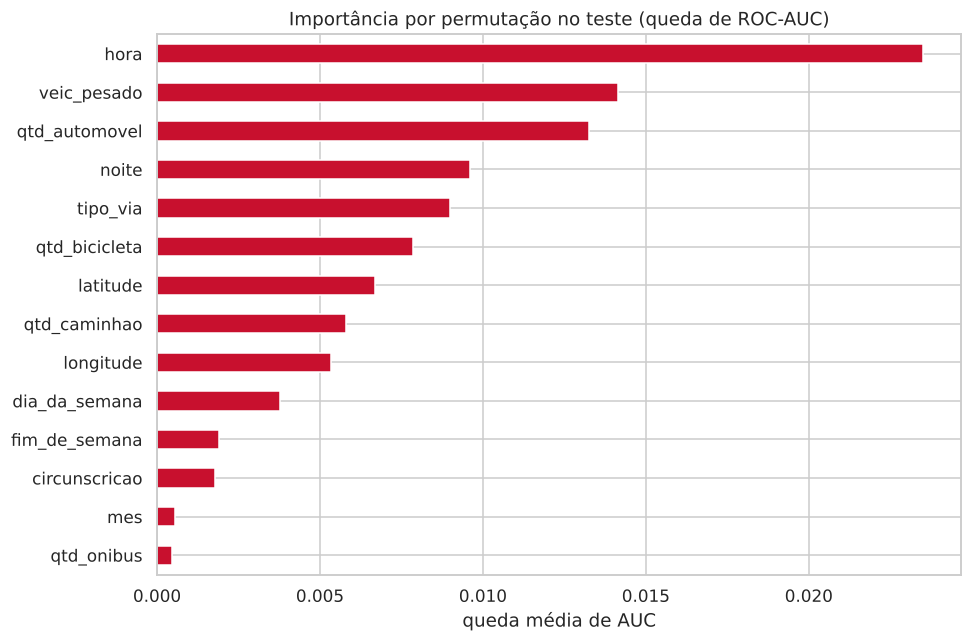

hora             0.0235
veic_pesado      0.0142
qtd_automovel    0.0133
noite            0.0096
tipo_via         0.0090
qtd_bicicleta    0.0079
latitude         0.0067
qtd_caminhao     0.0058
longitude        0.0053
dia_da_semana    0.0038
dtype: float64

In [14]:
perm = permutation_importance(modelo, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=CAT + NUM).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
imp.tail(14).plot.barh(ax=ax, color="#C8102E")
ax.set(title="Importância por permutação no teste (queda de ROC-AUC)", xlabel="queda média de AUC")
plt.tight_layout(); plt.savefig(FIG / "06_importancia.png", bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(4).head(10)

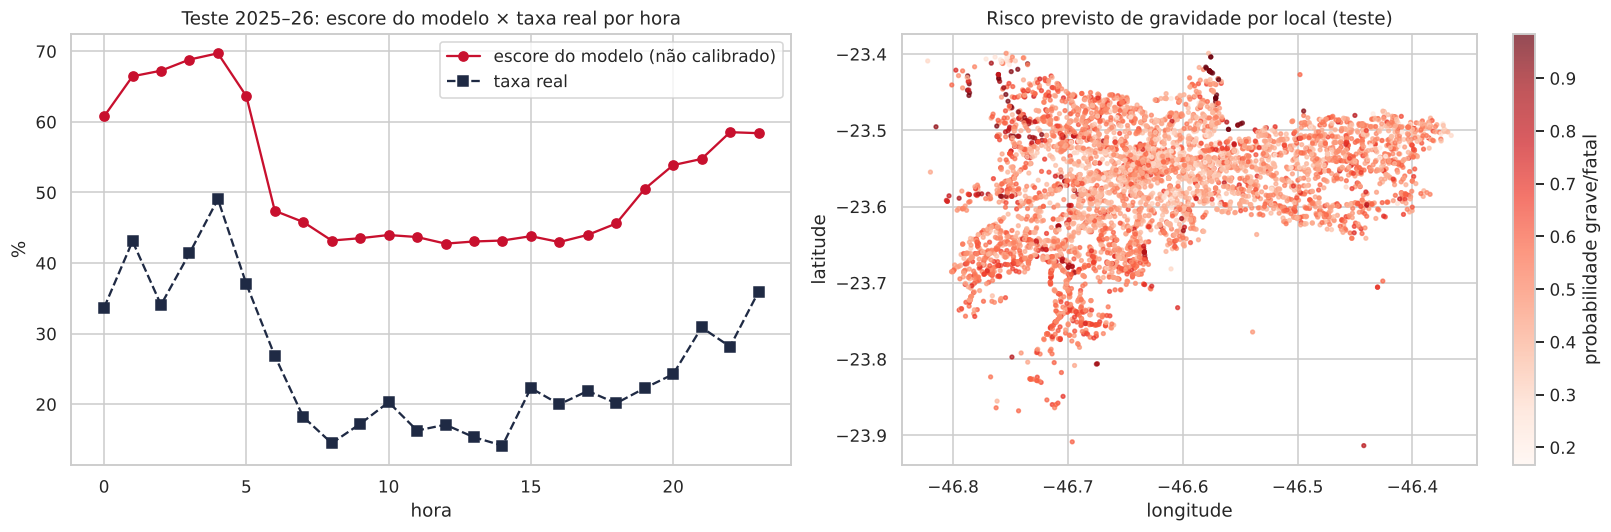

                prob  grave_ou_fatal
noite                               
dia (6h–18h)    44.0            18.6
noite (19h–5h)  56.5            29.2


In [15]:
teste_p = teste.assign(prob=modelo.predict_proba(X_te)[:, 1])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
h = teste_p[teste_p["hora"] >= 0].groupby("hora")[["prob", "grave_ou_fatal"]].mean() * 100
axes[0].plot(h.index, h["prob"], "o-", c="#C8102E", label="escore do modelo (não calibrado)")
axes[0].plot(h.index, h["grave_ou_fatal"], "s--", c="#1F2A44", label="taxa real")
axes[0].set(title="Teste 2025–26: escore do modelo × taxa real por hora", xlabel="hora", ylabel="%"); axes[0].legend()
g = teste_p.dropna(subset=["latitude", "longitude"])
sc = axes[1].scatter(g["longitude"], g["latitude"], c=g["prob"], cmap="Reds", s=6, alpha=0.7)
axes[1].set(title="Risco previsto de gravidade por local (teste)", xlabel="longitude", ylabel="latitude")
plt.colorbar(sc, ax=axes[1], label="probabilidade grave/fatal")
plt.tight_layout(); plt.savefig(FIG / "07_risco_hora_mapa.png", bbox_inches="tight"); plt.show()

dia_noite = teste_p.groupby("noite")[["prob", "grave_ou_fatal"]].mean().rename(index={0: "dia (6h–18h)", 1: "noite (19h–5h)"}) * 100
print(dia_noite.round(1))

> **Leitura do escore:** como o treino usa `scale_pos_weight` para compensar o desbalanceamento, a saída do modelo é um **escore de prioridade**, não uma probabilidade calibrada (fica acima da taxa real). O que importa é a **ordem**: horários e locais com escore maior concentram, de fato, mais casos graves.

## 5. Conclusão para o cidadão

As conclusões numéricas desta execução estão no `RELATORIO_ML.md`. Em resumo, a leitura para quem usa o SafeWalk:

* O modelo **não diz se uma rua é segura**; ele estima, a partir do histórico oficial, em que situações um atropelamento costuma ter consequência grave.
* Ele serve para o app **priorizar avisos** (ex.: destacar com mais ênfase trechos de via arterial à noite) e para o **painel da Prefeitura** priorizar fiscalização e iluminação.
* Limites: coordenadas do Infosiga têm precisão desconhecida; não há dados de volume de pedestres (exposição); sub-registro de casos leves pode inflar a proporção de graves.

In [16]:
import json, platform
info = {"linhas_total": int(len(df)), "treino": int(len(X_tr)), "teste": int(len(X_te)),
        "melhores_parametros": {k.replace("xgb__", ""): v for k, v in busca.best_params_.items()},
        "metricas": metr.to_dict(), "periodo": periodo, "python": platform.python_version()}
Path(FIG / "resumo_execucao.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=float))
print(json.dumps(info, indent=2, ensure_ascii=False, default=float))

{
  "linhas_total": 29410,
  "treino": 23778,
  "teste": 5632,
  "melhores_parametros": {
    "learning_rate": 0.03,
    "max_depth": 3,
    "n_estimators": 400
  },
  "metricas": {
    "XGBoost · treino": {
      "ROC-AUC": 0.681,
      "PR-AUC": 0.36,
      "Recall (grave)": 0.568,
      "Precisão (grave)": 0.279,
      "F1 (grave)": 0.374,
      "Acurácia balanceada": 0.631
    },
    "XGBoost · teste": {
      "ROC-AUC": 0.644,
      "PR-AUC": 0.351,
      "Recall (grave)": 0.528,
      "Precisão (grave)": 0.311,
      "F1 (grave)": 0.391,
      "Acurácia balanceada": 0.6
    },
    "Baseline aleatório · teste": {
      "ROC-AUC": 0.498,
      "PR-AUC": 0.218,
      "Recall (grave)": 0.164,
      "Precisão (grave)": 0.214,
      "F1 (grave)": 0.185,
      "Acurácia balanceada": 0.498
    }
  },
  "periodo": "01/01/2019 a 31/10/2026",
  "python": "3.13.18"
}
